Exercise 3.3

In [1]:
# Import relevant packages
import numpy as np
from cosamp import cosamp
import matplotlib.pyplot as plt

In [10]:
# setting the seed
np.random.seed(0)

# initial parameters
n, K  = 1000, 5 # signal size and sparsity
p = np.linspace(1,100,100)


# Creating the coefficient vector of sparsity 5 (with random complex values)
s = np.zeros(n, dtype=complex)
support = np.random.choice(n, size=K, replace=False)    
s[support] = np.random.rand(K) + 1j*np.random.rand(K)

# Creating the Fourier basis
Psi = np.fft.ifft(np.eye(n), axis=0, norm="ortho")

After the K-sparse vector s of Fourier coefficients in a Fourier basis can be calculated as x = $\Psi s$. Now the measurement vector y = $C \Psi s = \Theta s$ can be created based on a Gaussian random sampling matrix C (p x n) using a standard normal distribution. This is done for all p number of samples from 1 to 100 and for 10 randomly initialized C matrixes for all p-values.

In [ ]:
error_longlist0, error_longlist1, error_longlist2 = [], [], []
for i in range(1, len(p)+1):
    error_list0, error_list1, error_list2 = [], [], []
    for j in range(10):
        np.random.seed(j)
        C = np.random.randn(i, n)
        Theta = C @ Psi
        y = Theta @ s
        
        shat = cosamp(Theta,y,K,epsilon=1.e-10,max_iter=10)
        
        error = s - shat
        
        l2 = np.linalg.norm(error)/np.linalg.norm(s)
        error_list2.append(l2)
        
        l1 = np.linalg.norm(error, ord = 1)/np.linalg.norm(s, ord = 1)
        error_list1.append(l1)
        
        tol = 1e-10
        l0 = np.count_nonzero(np.abs(error) > tol)
        error_list0.append(l0)
        
        
    error_longlist0.append(error_list0)
    error_longlist1.append(error_list1)
    error_longlist2.append(error_list2)

/Users/mikkellevin/Library/CloudStorage/OneDrive-DanmarksTekniskeUniversitet/11. semester efterår 2026/02671 Data-Driven Methods for Computational Science and Engineering/Exercises/cosamp.py:26: ComplexWarning: Casting complex values to real discards the imaginary part
  b[omega], _, _, _ = np.linalg.lstsq(phiT, u)


Now its plotting time

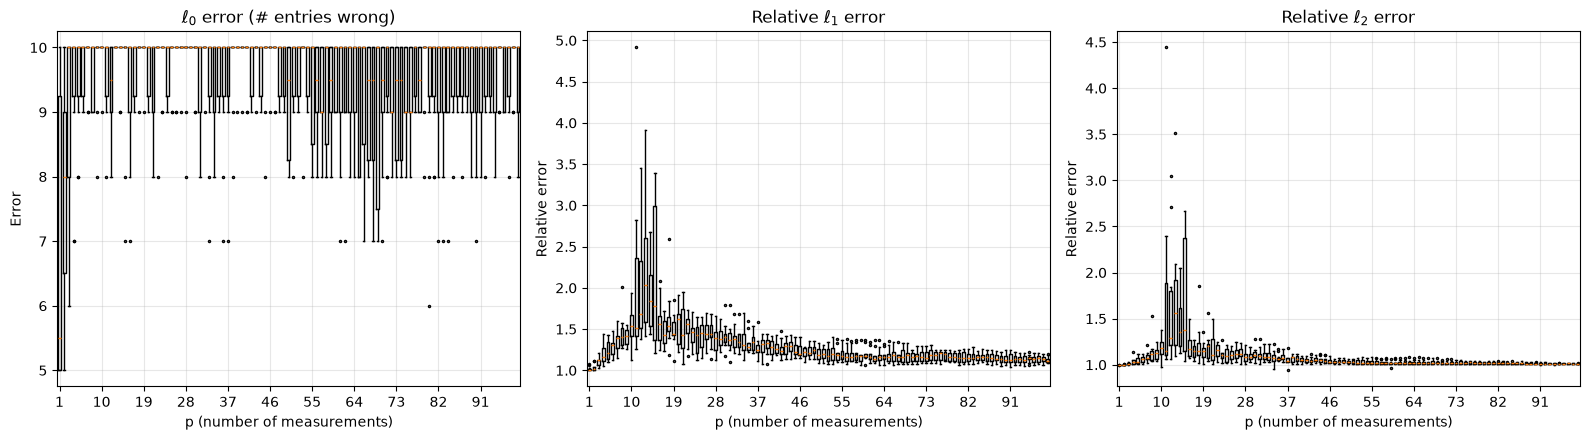

In [8]:
ps = np.arange(1, len(p))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
data = [error_longlist0, error_longlist1, error_longlist2]
titles = [r'$\ell_0$ error (# entries wrong)',
          r'Relative $\ell_1$ error',
          r'Relative $\ell_2$ error']

for ax, d, title in zip(axes, data, titles):
    ax.boxplot(d, positions=ps, widths=0.6, showfliers=True,
               flierprops=dict(marker='.', markersize=3))
    # Show a sparse set of x tick labels so they stay readable
    step = max(1, len(ps) // 10)
    ax.set_xticks(ps[::step])
    ax.set_xticklabels(ps[::step])
    ax.set_xlabel('p (number of measurements)')
    ax.set_title(title)
    ax.grid(alpha=0.3)

axes[0].set_ylabel('Error')
axes[1].set_ylabel('Relative error')
axes[2].set_ylabel('Relative error')

plt.tight_layout()
plt.show()

In [22]:
error_listK2 = []
for K in range(1, 21):
    np.random.seed(10 + K)
    s = np.zeros(n, dtype=complex)
    support = np.random.choice(n, size=K, replace=False)    
    s[support] = np.random.rand(K) + 1j * np.random.rand(K)
    error_listp2 = []
    for i in range(1, len(p)+1):
        error_listC2 = []
        for j in range(10):
            np.random.seed(j)
            C = np.random.randn(i, n)
            Theta = C @ Psi
            y = Theta @ s
            
            shat = cosamp(Theta,y,K,epsilon=1.e-10,max_iter=10)
            
            error = s - shat
            
            l2 = np.linalg.norm(error)/np.linalg.norm(s)
            error_listC2.append(l2)
            
        error_listp2.append(error_listC2)
    error_listK2.append(error_listp2)

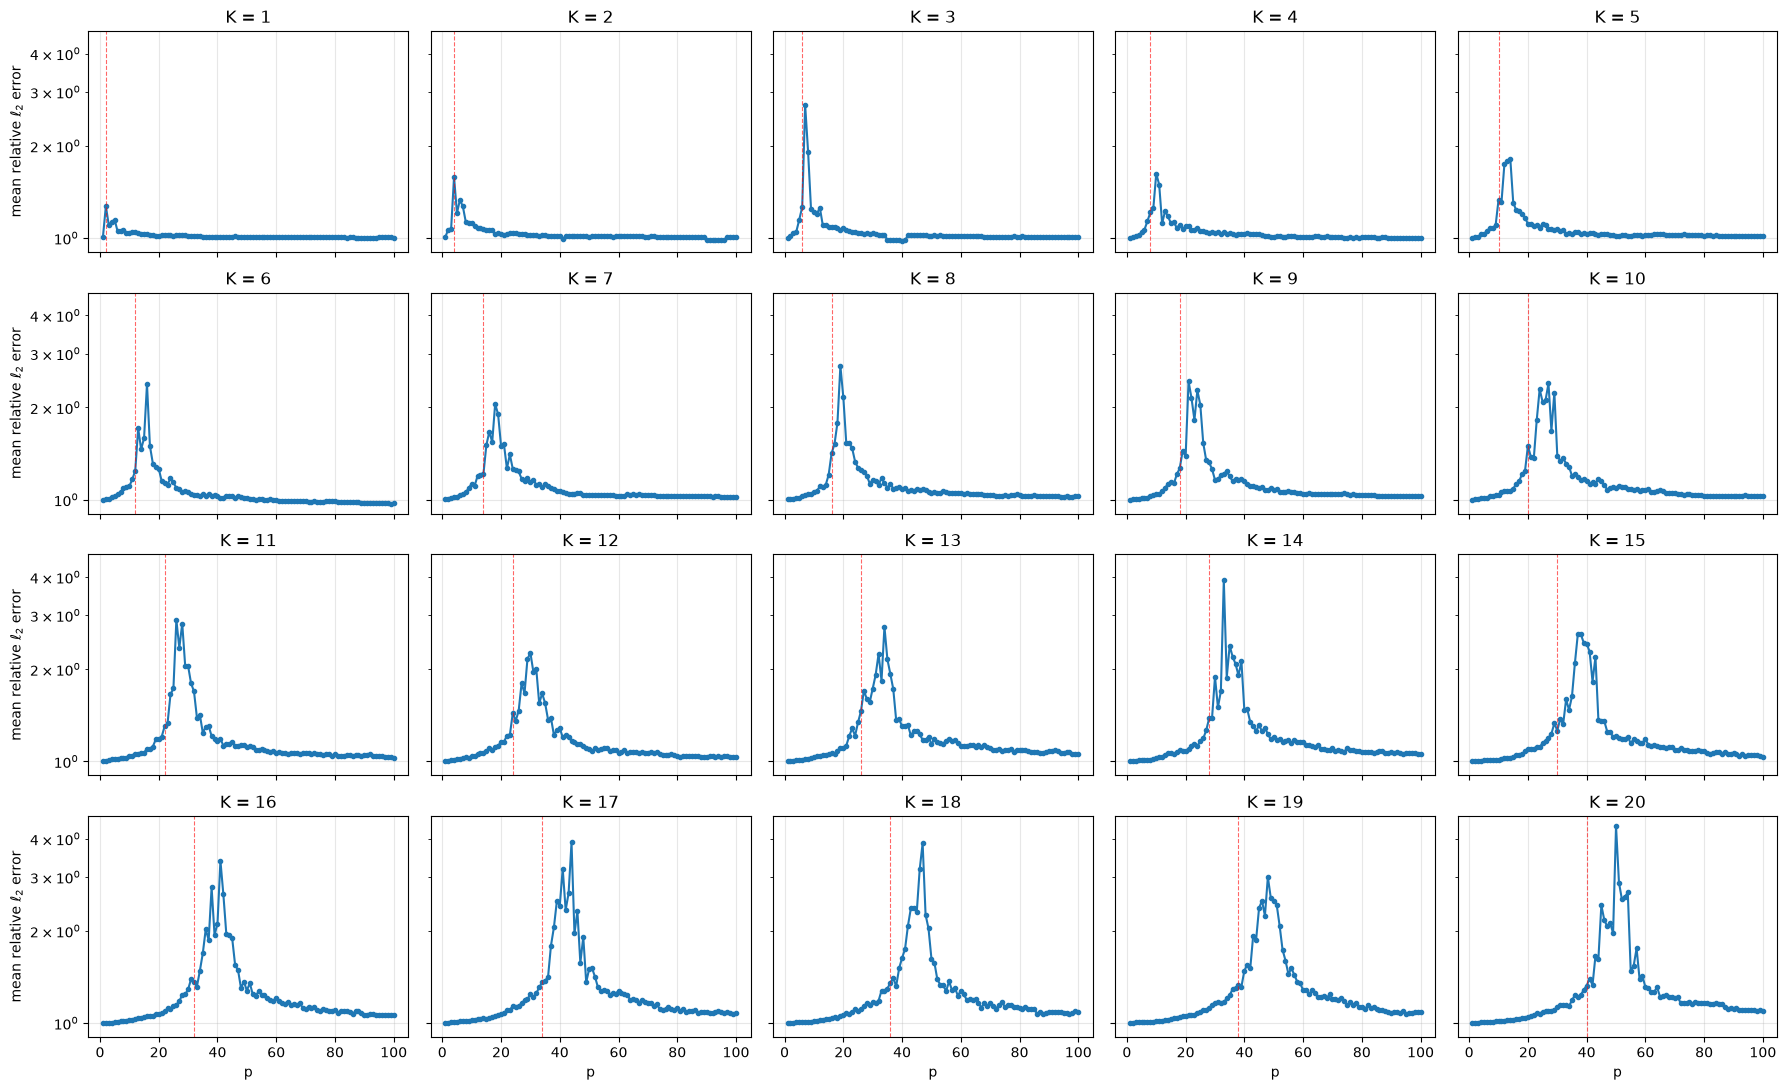

In [ ]:
err = np.array(error_listK2)            # shape (20, len(p), 10)
mean_err = err.mean(axis=2)             # average over the 10 trials -> (20, len(p))
ps = np.arange(1, len(p) + 1)           # matches range(1, len(p)+1) in the loop

fig, axes = plt.subplots(4, 5, figsize=(18, 11), sharex=True, sharey=True)

for K, ax in enumerate(axes.flat, start=1):
    ax.semilogy(ps, mean_err[K-1], 'o-', ms=3)
    ax.axvline(2*K, color='r', ls='--', lw=0.8, alpha=0.6) 
    ax.set_title(f'K = {K}')
    ax.grid(alpha=0.3)

for ax in axes[-1, :]:
    ax.set_xlabel('p')
for ax in axes[:, 0]:
    ax.set_ylabel(r'mean relative $\ell_2$ error')

plt.tight_layout()
plt.show()

In [24]:
K = 5
nList = [100,500,1000,2000,5000]
error_listn2 = []
for k, n in enumerate(nList):
    np.random.seed(10 + k)
    s = np.zeros(n, dtype=complex)
    support = np.random.choice(n, size=K, replace=False)    
    s[support] = np.random.rand(K) + 1j*np.random.rand(K)
    Psi = np.fft.ifft(np.eye(n), axis=0, norm="ortho")
    error_listp2 = []
    for i in range(1, len(p)+1):
        error_listC2 = []
        for j in range(10):
            np.random.seed(j)
            C = np.random.randn(i, n)
            Theta = C @ Psi
            y = Theta @ s
            
            shat = cosamp(Theta,y,K,epsilon=1.e-10,max_iter=10)
            
            error = s - shat
            
            l2 = np.linalg.norm(error)/np.linalg.norm(s)
            error_listC2.append(l2)
            
        error_listp2.append(error_listC2)
    error_listn2.append(error_listp2)

/Users/mikkellevin/Library/CloudStorage/OneDrive-DanmarksTekniskeUniversitet/11. semester efterår 2026/02671 Data-Driven Methods for Computational Science and Engineering/Exercises/cosamp.py:26: ComplexWarning: Casting complex values to real discards the imaginary part
  b[omega], _, _, _ = np.linalg.lstsq(phiT, u)


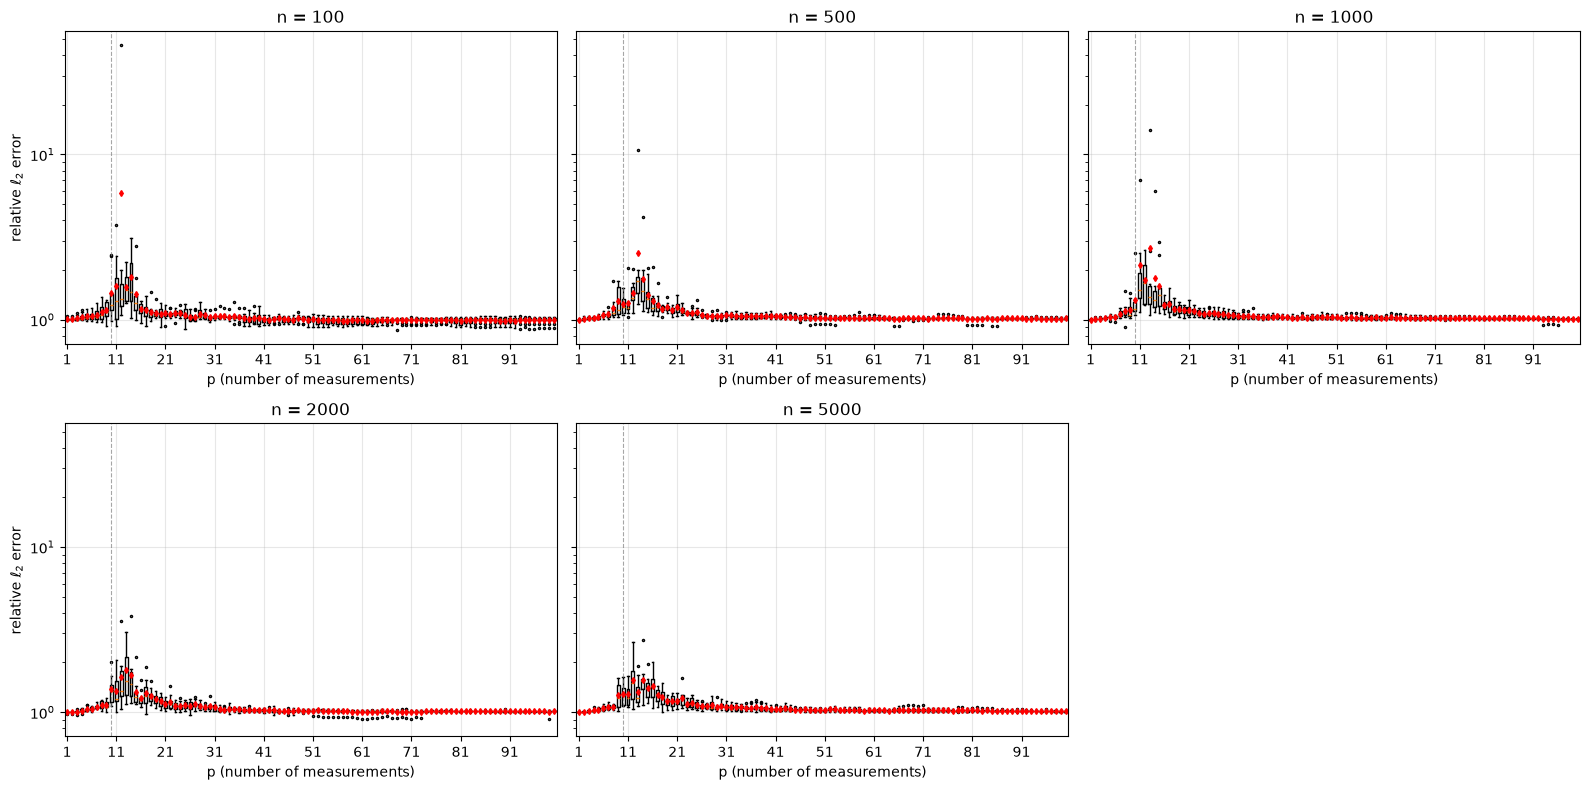

In [39]:
ps = np.arange(1, len(p) + 1)
floor = 1e-16                                   # keeps exact zeros visible on a log axis

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharey=True)

for ax, n_val, err_p in zip(axes.flat, nList, error_listn2):
    data = [np.maximum(e, floor) for e in err_p]          # list of len(p) arrays of 10 trials
    ax.boxplot(data, positions=ps, widths=0.6, showmeans=True,
               flierprops=dict(marker='.', markersize=3),
               meanprops=dict(marker='d', markerfacecolor='r',
                              markeredgecolor='r', markersize=3))
    ax.set_yscale('log')
    ax.axvline(2*K, color='gray', ls='--', lw=0.8, alpha=0.7)   # p = 2K reference
    step = max(1, len(ps) // 10)
    ax.set_xticks(ps[::step])
    ax.set_xticklabels(ps[::step])
    ax.set_title(f'n = {n_val}')
    ax.set_xlabel('p (number of measurements)')
    ax.grid(alpha=0.3)

for ax in axes[:, 0]:
    ax.set_ylabel(r'relative $\ell_2$ error')

axes.flat[-1].axis('off')                   
plt.tight_layout()
plt.show()

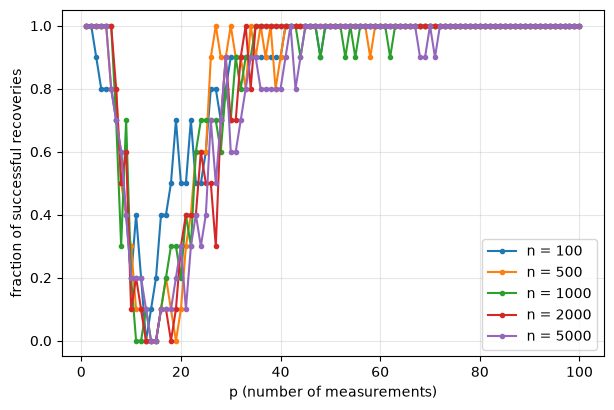

In [36]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for n_val, err_p in zip(nList, error_listn2):
    err = np.array(err_p)                              # (len(p), 10)
    success = (err < 1.1).mean(axis=1)                # fraction of trials that recovered
    ax.plot(ps, success, 'o-', ms=3, label=f'n = {n_val}')
ax.set_xlabel('p (number of measurements)')
ax.set_ylabel('fraction of successful recoveries')
ax.legend(); ax.grid(alpha=0.3)
plt.show()